# EDA — US Accidents Dataset

**Goal:** explore, understand and clean the dataset before the advanced statistical analysis (`02`–`05`).

**Design of this pipeline (important):**
- The **full raw file** (~7.7M rows) is loaded **once**. Everything that must be exact — temporal coverage, duplicates, missing values — is computed on the **full data**.
- A reproducible **random sample of 500,000 rows** is then drawn for the statistical tests (notebooks 02, 04, 05).
- The exact **monthly accident counts of the full data** are exported separately for the time-series notebook (03), because counting accidents on a sample would distort the series.

**Outputs of this notebook:**
- `US_Accidents_Sample500k_Clean.csv` 
- `monthly_counts_full.csv` 

**Contents:**
1. Loading the full raw dataset
2. Duplicates and inconsistencies
3. Temporal coverage check
4. Missing values analysis
5. Random sample
6. Imputation
7. Distribution of key variables
8. First exploratory visualizations
9. Export

---


## 0. Configuration and imports

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

DATA_DIR = Path("D:/Accidents_USA/Dataset")
RAW_PATH = DATA_DIR / "D:/Accidents_USA/Dataset/US_Accidents.csv"                      
SAMPLE_PATH = DATA_DIR / "D:/Accidents_USA/Dataset/US_Accidents_Sample500k_Clean.csv"  
MONTHLY_PATH = DATA_DIR / "D:/Accidents_USA/Dataset/monthly_counts_full.csv"           

SAMPLE_SIZE = 500_000
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (10, 5)


## 1. Loading the full raw dataset


In [5]:
USE_COLS = [
    'ID', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Distance(mi)',
    'City', 'State', 'Timezone',
    'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)',
    'Precipitation(in)', 'Weather_Condition',
    'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout',
    'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop',
    'Sunrise_Sunset'
]

df = pd.read_csv(RAW_PATH, usecols=USE_COLS)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()


Shape: 1,410,124 rows x 31 columns
Memory: 0.88 GB


,ID,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),City,State,Timezone,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset
0,A-1,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,0.01,Dayton,OH,US/Eastern,36.9,91.0,29.68,10.0,8.1,0.02,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night
1,A-2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,0.01,Reynoldsburg,OH,US/Eastern,37.9,100.0,29.65,10.0,8.1,0.00,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night
2,A-3,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,0.01,Williamsburg,OH,US/Eastern,36.0,100.0,29.67,10.0,3.5,NaN,Overcast,False,False,False,False,False,False,False,False,False,False,False,True,False,Night
3,A-4,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,0.01,Dayton,OH,US/Eastern,35.1,96.0,29.64,9.0,4.6,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,False,Night
4,A-5,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,0.01,Dayton,OH,US/Eastern,36.0,89.0,29.65,6.0,3.5,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,True,False,Day


### 1.1 Parsing the dates robustly



In [ ]:
def parse_datetime_safe(series):
    s
    return pd.to_datetime(series.astype(str).str.slice(0, 19), format='%Y-%m-%d %H:%M:%S', errors='coerce')

df['Start_Time'] = parse_datetime_safe(df['Start_Time'])
df['End_Time'] = parse_datetime_safe(df['End_Time'])

n_nat = df['Start_Time'].isna().sum()
print(f"Unparseable Start_Time (NaT): {n_nat:,} ({n_nat / len(df) * 100:.4f}%)")
print(f"Date range: {df['Start_Time'].min()} -> {df['Start_Time'].max()}")


Unparseable Start_Time (NaT): 0 (0.0000%)
Date range: 2016-02-08 05:46:00 -> 2022-09-08 17:56:22


### 1.2 General inspection

In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1410124 entries, 0 to 1410123
Data columns (total 31 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   ID                 1410124 non-null  object        
 1   Severity           1410124 non-null  int64         
 2   Start_Time         1410124 non-null  datetime64[ns]
 3   End_Time           1410124 non-null  datetime64[ns]
 4   Start_Lat          1410124 non-null  float64       
 5   Start_Lng          1410124 non-null  float64       
 6   Distance(mi)       1410124 non-null  float64       
 7   City               1410091 non-null  object        
 8   State              1410124 non-null  object        
 9   Timezone           1409314 non-null  object        
 10  Temperature(F)     1410124 non-null  float64       
 11  Humidity(%)        1410124 non-null  float64       
 12  Pressure(in)       1410124 non-null  float64       
 13  Visibility(mi)     1410124 

In [8]:
df.describe(include='number').T


,count,mean,std,min,25%,50%,75%,max
Severity,1410124.0,2.326064,0.533959,1.000000,2.000000,2.000000,3.000000,4.000000
Start_Lat,1410124.0,36.086825,4.875690,24.554800,33.025877,35.377190,40.092905,48.998085
Start_Lng,1410124.0,-94.081716,16.987271,-124.497414,-117.043617,-87.646439,-80.883217,-67.553307
Distance(mi),1410124.0,0.203076,1.621298,0.000000,0.000000,0.000000,0.010000,441.750000
Temperature(F),1410124.0,63.221368,17.734388,-77.800000,52.000000,65.000000,76.000000,203.000000
Humidity(%),1410124.0,65.960628,22.122005,1.000000,50.000000,68.000000,84.000000,100.000000
Pressure(in),1410124.0,29.598897,0.878453,0.120000,29.400000,29.860000,30.020000,58.320000
Visibility(mi),1410124.0,9.142755,2.374603,0.000000,10.000000,10.000000,10.000000,111.000000
Wind_Speed(mph),1410124.0,7.538537,5.202913,0.000000,5.000000,7.000000,10.000000,822.800000
Precipitation(in),917977.0,0.010187,0.156142,0.000000,0.000000,0.000000,0.000000,36.470000


In [9]:
df.describe(include='object').T


,count,unique,top,freq
ID,1410124,1410124,A-1,1
City,1410091,9598,Houston,50749
State,1410124,49,CA,322491
Timezone,1409314,4,US/Eastern,646505
Weather_Condition,1384033,116,Fair,424940
Sunrise_Sunset,1408482,2,Day,1017092


---
## 2. Duplicates and inconsistencies (full data)

In [10]:
n_duplicates = df.duplicated(subset=['ID']).sum()
n_bad_dates = (df['End_Time'] < df['Start_Time']).sum()

print(f"Duplicated IDs: {n_duplicates:,}")
print(f"Rows where End_Time < Start_Time: {n_bad_dates:,}")


Duplicated IDs: 0
Rows where End_Time < Start_Time: 0


In [ ]:
rows_before = len(df)

df = df.drop_duplicates(subset=['ID'])
df = df.dropna(subset=['Start_Time'])   

print(f"Rows before: {rows_before:,} | rows after: {len(df):,} | removed: {rows_before - len(df):,}")


Rows before: 1,410,124 | rows after: 1,410,124 | removed: 0


---
## 3. Temporal coverage check (full data)



In [ ]:
monthly_counts = (
    df.set_index('Start_Time')
      .resample('MS')
      .size()
      .rename('accident_count')
)

full_range = pd.date_range(monthly_counts.index.min(), monthly_counts.index.max(), freq='MS')
monthly_counts = monthly_counts.reindex(full_range, fill_value=0)
monthly_counts.index.name = 'month'

print(f"Months between first and last record: {len(monthly_counts)}")
print(f"Months with ZERO accidents: {(monthly_counts == 0).sum()}")


Months between first and last record: 80
Months with ZERO accidents: 35


In [13]:
# Full table, no truncation
with pd.option_context('display.max_rows', None):
    display(monthly_counts.to_frame())


,accident_count
month,
2016-02-01,425
2016-03-01,3871
2016-04-01,12059
2016-05-01,10235
2016-06-01,20432
2016-07-01,30761
2016-08-01,38541
2016-09-01,39565
2016-10-01,38185


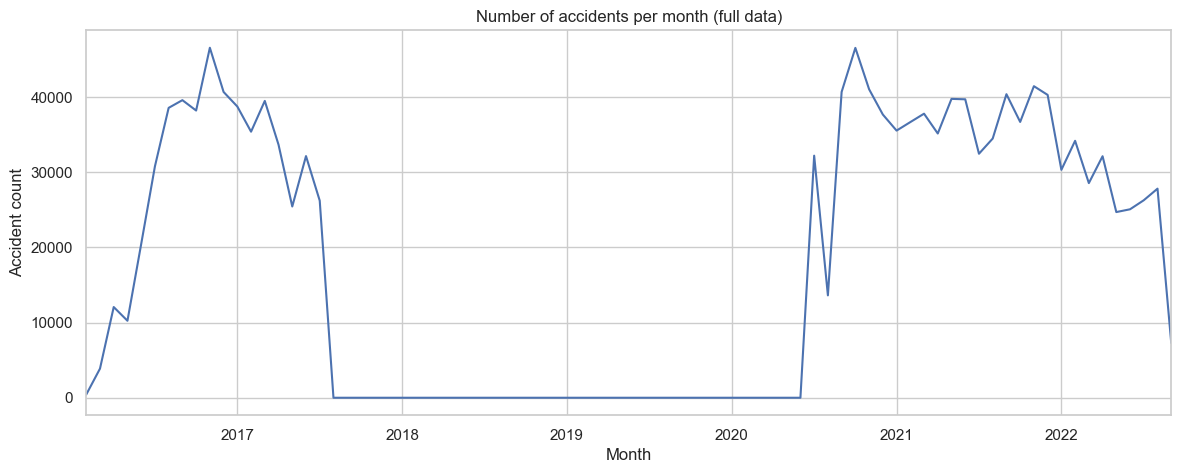

In [14]:
plt.figure(figsize=(14, 5))
monthly_counts.plot()
plt.title("Number of accidents per month (full data)")
plt.xlabel("Month")
plt.ylabel("Accident count")
plt.show()


In [15]:
monthly_counts.to_csv(MONTHLY_PATH)
print(f"Saved: {MONTHLY_PATH}")


Saved: D:\Accidents_USA\Dataset\monthly_counts_full.csv


---
## 4. Missing values analysis (full data)

In [16]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'n_missing': missing, 'pct_missing': missing_pct})
missing_summary = missing_summary[missing_summary['n_missing'] > 0]
missing_summary


,n_missing,pct_missing
Precipitation(in),492147,34.90
Weather_Condition,26091,1.85
Sunrise_Sunset,1642,0.12
Timezone,810,0.06
City,33,0.00


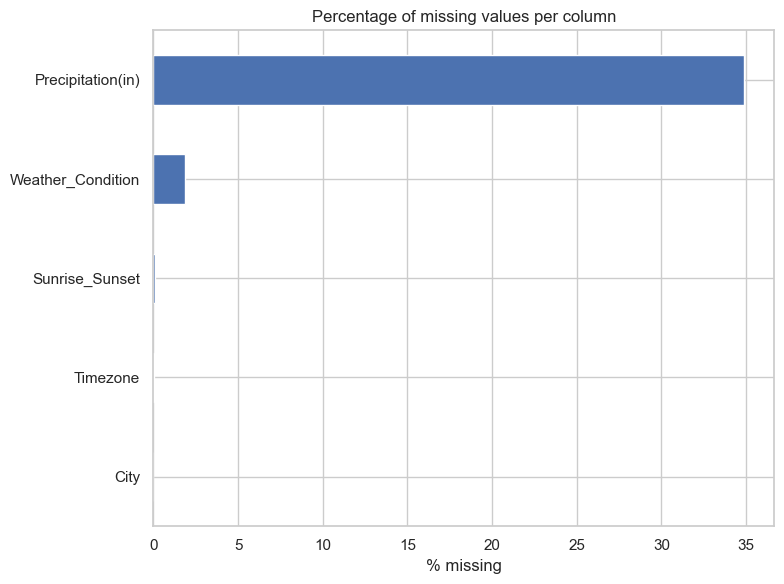

In [17]:
plt.figure(figsize=(8, 6))
missing_summary['pct_missing'].sort_values().plot(kind='barh')
plt.title("Percentage of missing values per column")
plt.xlabel("% missing")
plt.tight_layout()
plt.show()


### 4.1 Type of missingness (MCAR / MAR / MNAR)



In [18]:
missing_flag = df['Visibility(mi)'].isna()

missing_rate_by_state = missing_flag.groupby(df['State']).mean().sort_values(ascending=False)
display(missing_rate_by_state.head(10))

contingency = pd.crosstab(df['State'], missing_flag)
chi2, p_value, dof, _ = stats.chi2_contingency(contingency)
n = contingency.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

print(f"Chi2 = {chi2:.2f}, p-value = {p_value:.4g}, Cramer's V = {cramers_v:.4f}")


State
AL    0.0
AR    0.0
AZ    0.0
CA    0.0
CO    0.0
CT    0.0
DC    0.0
DE    0.0
FL    0.0
GA    0.0
Name: Visibility(mi), dtype: float64

Chi2 = 0.00, p-value = 1, Cramer's V = nan


C:\Users\poste\AppData\Local\Temp\ipykernel_20060\1126645623.py:9: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))


---
## 5. Random sample



Sample shape: 500,000 rows x 31 columns


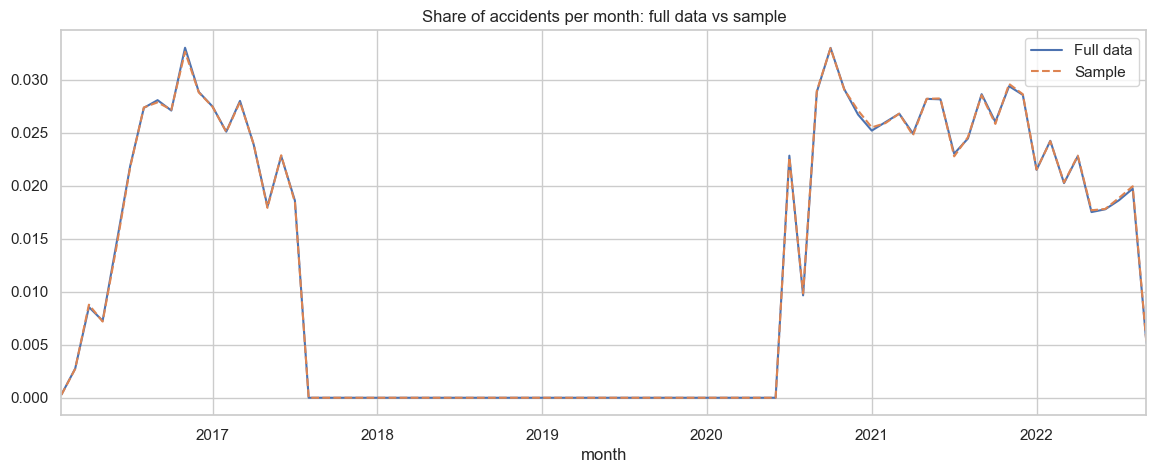

,full,sample
Severity,,
1,0.027293,0.027682
2,0.624741,0.624254
3,0.342576,0.342720
4,0.005390,0.005344


In [19]:
sample = df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).copy()
print(f"Sample shape: {sample.shape[0]:,} rows x {sample.shape[1]} columns")

# 1) Same share of accidents per month as the full data?
full_share = monthly_counts / monthly_counts.sum()
sample_monthly = sample.set_index('Start_Time').resample('MS').size().reindex(monthly_counts.index, fill_value=0)
sample_share = sample_monthly / sample_monthly.sum()

plt.figure(figsize=(14, 5))
full_share.plot(label='Full data')
sample_share.plot(label='Sample', linestyle='--')
plt.title("Share of accidents per month: full data vs sample")
plt.legend()
plt.show()

# 2) Same Severity distribution?
pd.concat([
    df['Severity'].value_counts(normalize=True).rename('full'),
    sample['Severity'].value_counts(normalize=True).rename('sample')
], axis=1).sort_index()


In [ ]:
del df
import gc
gc.collect()


13100

---
## 6. Imputation (on the sample)

In [21]:
cols_impute_median = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)']

print("Missing before imputation:")
display(sample[cols_impute_median].isna().sum())

for col in cols_impute_median:
    # median of the State, so regional climate differences are preserved
    sample[col] = sample.groupby('State')[col].transform(lambda x: x.fillna(x.median()))
    # global fallback if a whole State has no value for that column
    sample[col] = sample[col].fillna(sample[col].median())

print("Missing after imputation:")
display(sample[cols_impute_median].isna().sum())


Missing before imputation:


Temperature(F)     0
Humidity(%)        0
Pressure(in)       0
Visibility(mi)     0
Wind_Speed(mph)    0
dtype: int64

Missing after imputation:


Temperature(F)     0
Humidity(%)        0
Pressure(in)       0
Visibility(mi)     0
Wind_Speed(mph)    0
dtype: int64

---
## 7. Distribution of key variables (sample)

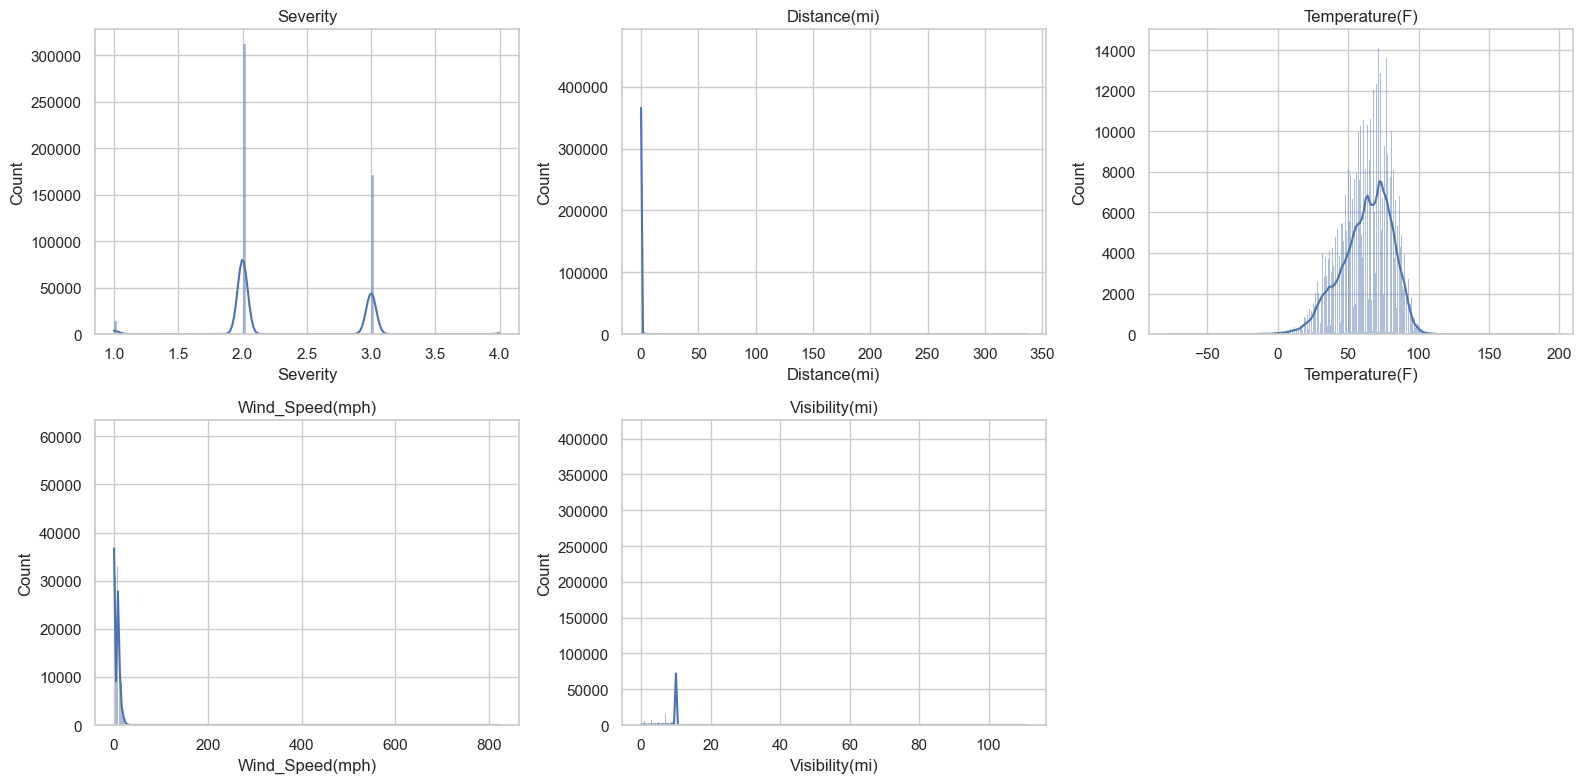

In [22]:
key_numeric_cols = ['Severity', 'Distance(mi)', 'Temperature(F)', 'Wind_Speed(mph)', 'Visibility(mi)']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, key_numeric_cols):
    sns.histplot(sample[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()


In [23]:
for col in key_numeric_cols:
    skew = sample[col].skew()
    kurt = sample[col].kurtosis()
    print(f"{col}: skewness={skew:.2f}, kurtosis={kurt:.2f}")


Severity: skewness=0.29, kurtosis=-0.48
Distance(mi): skewness=44.74, kurtosis=5496.00
Temperature(F): skewness=-0.55, kurtosis=0.10
Wind_Speed(mph): skewness=16.27, kurtosis=2334.45
Visibility(mi): skewness=0.55, kurtosis=74.45


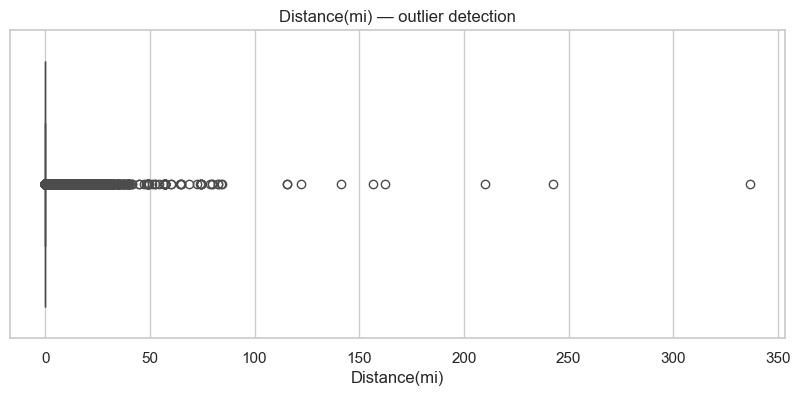

IQR = 0.010, outlier bounds: [-0.015, 0.025]
Share of outliers: 6.5%


In [24]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=sample['Distance(mi)'])
plt.title("Distance(mi) — outlier detection")
plt.show()

q1, q3 = sample['Distance(mi)'].quantile([0.25, 0.75])
iqr = q3 - q1
print(f"IQR = {iqr:.3f}, outlier bounds: [{q1 - 1.5 * iqr:.3f}, {q3 + 1.5 * iqr:.3f}]")
print(f"Share of outliers: {((sample['Distance(mi)'] > q3 + 1.5 * iqr).mean() * 100):.1f}%")


---
## 8. First exploratory visualizations (sample)

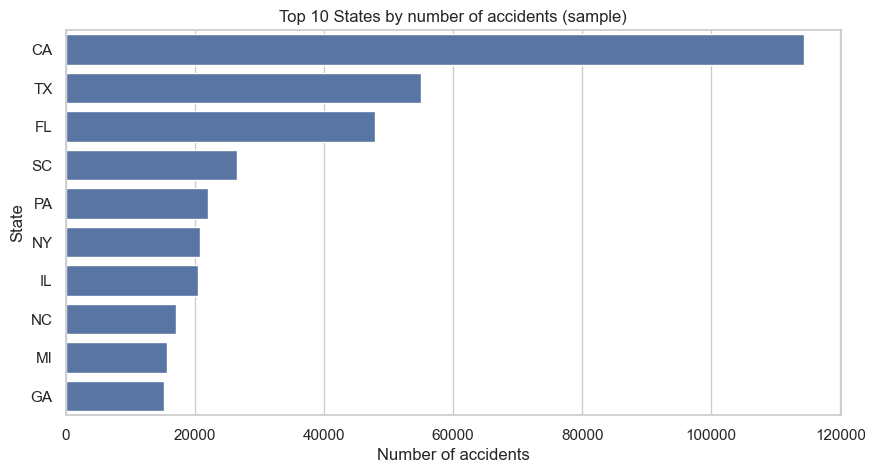

In [25]:
top_states = sample['State'].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_states.values, y=top_states.index, orient='h')
plt.title("Top 10 States by number of accidents (sample)")
plt.xlabel("Number of accidents")
plt.show()


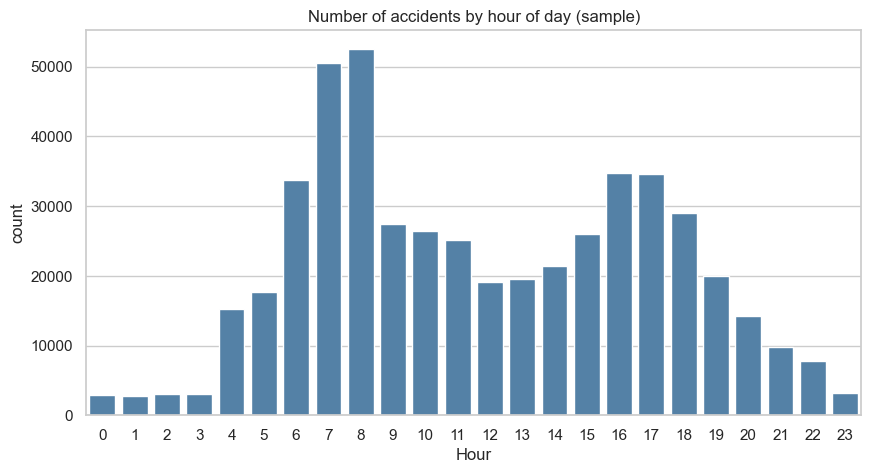

In [26]:
sample['hour'] = sample['Start_Time'].dt.hour
plt.figure(figsize=(10, 5))
sns.countplot(x='hour', data=sample, color='steelblue')
plt.title("Number of accidents by hour of day (sample)")
plt.xlabel("Hour")
plt.show()


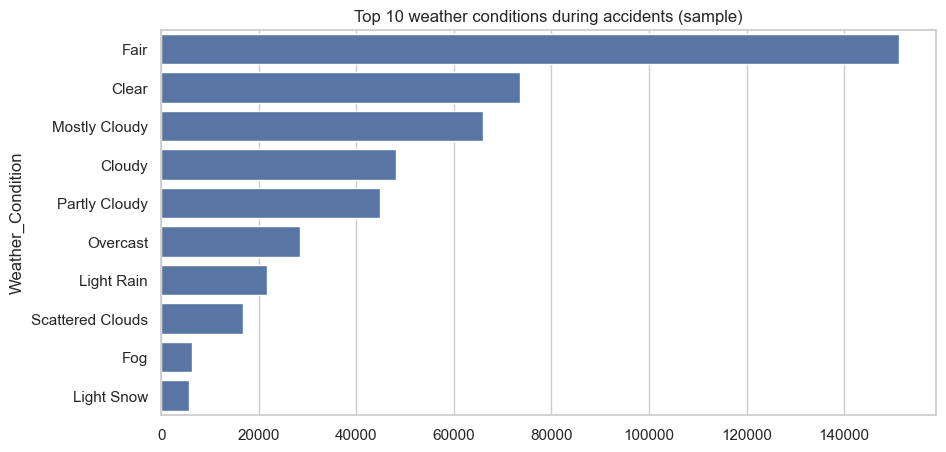

In [27]:
weather_counts = sample['Weather_Condition'].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=weather_counts.values, y=weather_counts.index, orient='h')
plt.title("Top 10 weather conditions during accidents (sample)")
plt.show()


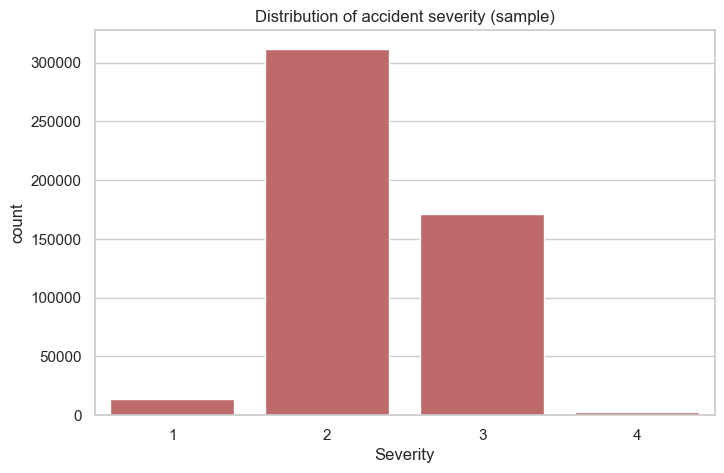

In [28]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Severity', data=sample, color='indianred')
plt.title("Distribution of accident severity (sample)")
plt.show()


---
## 9. Export

In [29]:
sample.to_csv(SAMPLE_PATH, index=False)

# Sanity check: read the file back
check = pd.read_csv(SAMPLE_PATH, parse_dates=['Start_Time'], usecols=['Start_Time', 'Severity'])
print(f"Exported: {SAMPLE_PATH}")
print(f"Rows read back: {len(check):,}")
print(f"Date range: {check['Start_Time'].min()} -> {check['Start_Time'].max()}")
print(f"Monthly counts file: {MONTHLY_PATH}")


Exported: D:\Accidents_USA\Dataset\US_Accidents_Sample500k_Clean.csv
Rows read back: 500,000
Date range: 2016-02-08 06:49:27 -> 2022-09-08 17:56:22
Monthly counts file: D:\Accidents_USA\Dataset\monthly_counts_full.csv


In [30]:
print("Folder used by the notebook:", DATA_DIR.resolve())
for p in sorted(DATA_DIR.iterdir()):
    print(f"{p.name:45s} {p.stat().st_size / 1e6:10.1f} MB")

Folder used by the notebook: D:\Accidents_USA\Dataset
monthly_counts_full.csv                              0.0 MB
US_Accidents.csv                                   536.6 MB
US_Accidents_Clean.csv                             301.2 MB
US_Accidents_Sample500k_Clean.csv                  112.6 MB
